In [1]:
%pip install pandas matplotlib wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from wordcloud import WordCloud, STOPWORDS
import os

# Download dataset from Kaggle
path = kagglehub.dataset_download(
    "niraliivaghani/flipkart-product-customer-reviews-dataset"
)

print("Path to dataset files:", path)

# Find CSV file
csv_files = [
    f for f in os.listdir(path)
    if f.endswith(".csv")
]

print("Available CSV files:", csv_files)

# Load CSV into DataFrame
df = pd.read_csv(os.path.join(path, csv_files[0]))

# Display first five records
df.head()


Path to dataset files: C:\Users\HLBS\.cache\kagglehub\datasets\niraliivaghani\flipkart-product-customer-reviews-dataset\versions\1
Available CSV files: ['Dataset-SA.csv']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [11]:

product_col = "product_name"
rating_col = "Rate"
price_col = "product_price"
summary_col = "Summary"

print("Columns selected successfully!")


Columns selected successfully!


In [12]:

# Clean rating
df[rating_col] = pd.to_numeric(
    df[rating_col].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Clean price
df[price_col] = pd.to_numeric(
    df[price_col].astype(str)
      .str.replace(",", "", regex=False)
      .str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Remove missing values
df = df.dropna(subset=[
    product_col, rating_col, price_col
])

print("Data cleaning completed!")
df.head()


Data cleaning completed!


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5.0,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1.0,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3.0,fair,ok ok product,neutral


In [13]:

items = df.groupby("product_name").agg(
    mean_rating=("Rate", "mean"),
    mean_price=("product_price", "mean")
).reset_index()

items.head(10)


,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.986667,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.406915,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.888889,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.670000,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.750000,199.0
5,77085PP03 Volt Analog Watch For Men,4.711111,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.687500,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.803571,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.516129,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.455000,279.0


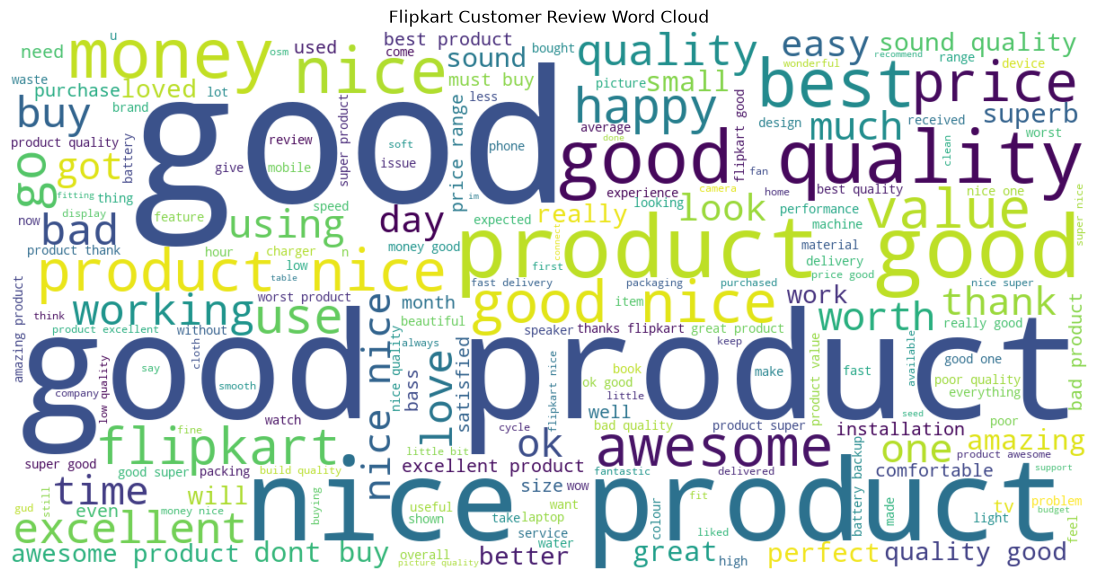

In [14]:

text = " ".join(df["Summary"].dropna().astype(str))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Flipkart Customer Review Word Cloud")
plt.show()
